# Correlation and multicollinearity audit

This Data Lead audit checks relationships among approved model inputs. It uses Spearman correlation and numeric VIF for numeric features, plus bias-corrected Cramer's V for categorical features. Correlation is not a timing decision: after-the-fact fields remain forbidden regardless of their measured association.

In [11]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SRC_DIR = Path.cwd().parent / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

import data
import features
from models.classifiers import NUMERICAL_FEATURES, CATEGORICAL_FEATURES

raw = data.read_raw()
bookings = features.prepare_bookings(raw)
numeric = bookings[NUMERICAL_FEATURES]
categorical = bookings[CATEGORICAL_FEATURES].astype("string")
print(f"Audited {len(bookings):,} bookings and {len(NUMERICAL_FEATURES) + len(CATEGORICAL_FEATURES)} model features.")

from matplotlib.patches import Patch

def add_chart_legend(ax):
    """Add a plain-language key when a chart has no existing legend."""
    if ax.get_legend() is not None or ax.get_ylabel() == "":
        return
    handles, labels = ax.get_legend_handles_labels()
    if handles:
        ax.legend(title="How to read this chart")
        return
    color = "#777777"
    if ax.patches:
        color = ax.patches[0].get_facecolor()
    elif ax.lines:
        color = ax.lines[0].get_color()
    label = f"Bars/lines show {ax.get_ylabel().lower()}"
    ax.legend(handles=[Patch(facecolor=color, label=label)], title="How to read this chart")


Audited 119,390 bookings and 22 model features.


## 1. Numeric correlation and VIF


In [12]:
spearman = numeric.corr(method="spearman")
pairs = []
for i, first in enumerate(spearman.columns):
    for second in spearman.columns[i + 1:]:
        value = spearman.loc[first, second]
        pairs.append({"feature_1": first, "feature_2": second, "spearman": value, "absolute_spearman": abs(value)})
numeric_pairs = pd.DataFrame(pairs).sort_values("absolute_spearman", ascending=False)
display(numeric_pairs.head(15).round(3))

standardized = (numeric - numeric.mean()) / numeric.std(ddof=0)
matrix = np.column_stack([np.ones(len(standardized)), standardized.to_numpy()])
vif_rows = []
for position, feature in enumerate(NUMERICAL_FEATURES, start=1):
    target = matrix[:, position]
    other_columns = np.delete(matrix, position, axis=1)
    coefficients = np.linalg.lstsq(other_columns, target, rcond=None)[0]
    prediction = other_columns @ coefficients
    r_squared = 1 - ((target - prediction) ** 2).sum() / ((target - target.mean()) ** 2).sum()
    vif_rows.append({"feature": feature, "vif": 1 / (1 - r_squared)})
vif = pd.DataFrame(vif_rows).sort_values("vif", ascending=False)
display(vif.round(3))


,feature_1,feature_2,spearman,absolute_spearman
53,is_repeated_guest,previous_bookings_not_canceled,0.757,0.757
3,lead_time,stays_in_week_nights,0.296,0.296
27,stays_in_weekend_nights,stays_in_week_nights,0.238,0.238
44,adults,previous_bookings_not_canceled,-0.210,0.210
4,lead_time,adults,0.192,0.192
7,lead_time,is_repeated_guest,-0.190,0.190
9,lead_time,previous_bookings_not_canceled,-0.189,0.189
42,adults,is_repeated_guest,-0.177,0.177
8,lead_time,previous_cancellations,0.171,0.171
2,lead_time,stays_in_weekend_nights,0.162,0.162


,feature,vif
4,stays_in_week_nights,1.366
3,stays_in_weekend_nights,1.338
8,is_repeated_guest,1.246
10,previous_bookings_not_canceled,1.238
0,lead_time,1.080
5,adults,1.043
9,previous_cancellations,1.037
1,arrival_date_week_number,1.023
6,children,1.008
2,arrival_date_day_of_month,1.007


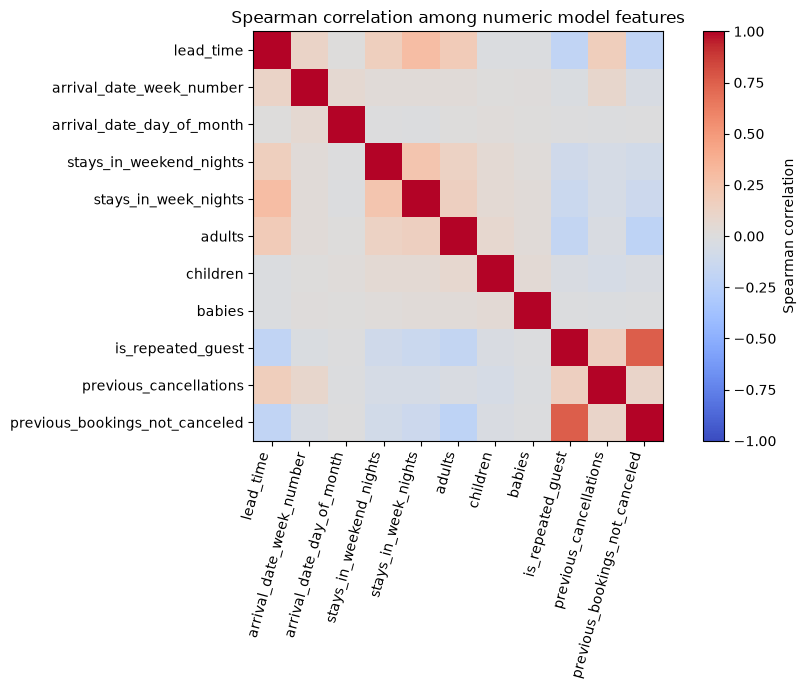

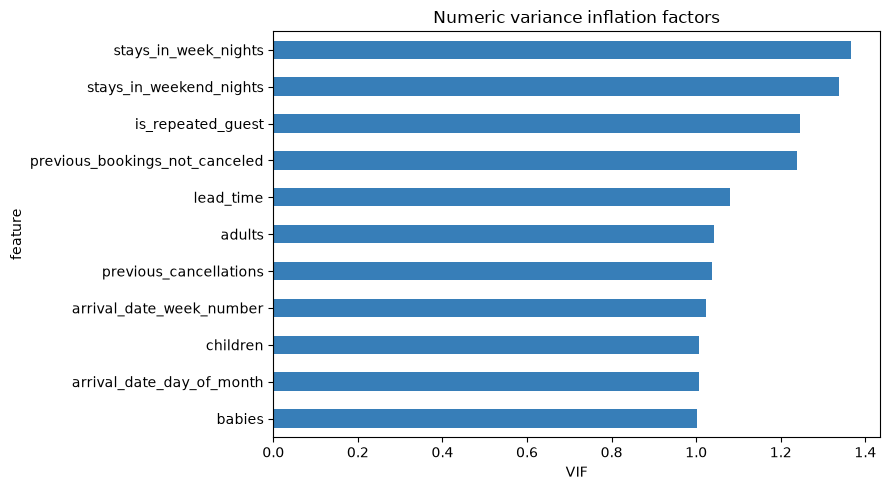

In [13]:
fig, ax = plt.subplots(figsize=(10, 7))
im = ax.imshow(spearman, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(spearman.columns)), spearman.columns, rotation=75, ha="right")
ax.set_yticks(range(len(spearman.index)), spearman.index)
ax.set_title("Spearman correlation among numeric model features")
fig.colorbar(im, ax=ax, label="Spearman correlation")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
vif.sort_values("vif").plot.barh(x="feature", y="vif", ax=ax, legend=False, color="#377eb8")
ax.set_title("Numeric variance inflation factors")
ax.set_xlabel("VIF")
fig.tight_layout()
plt.show()


## 2. Categorical association


In [14]:
def cramers_v(first, second):
    table = pd.crosstab(first, second).to_numpy()
    total = table.sum()
    expected = table.sum(axis=1, keepdims=True) * table.sum(axis=0, keepdims=True) / total
    chi_square = ((table - expected) ** 2 / expected).sum()
    rows, columns = table.shape
    phi_squared = max(0, chi_square / total - (columns - 1) * (rows - 1) / (total - 1))
    corrected_rows = rows - (rows - 1) ** 2 / (total - 1)
    corrected_columns = columns - (columns - 1) ** 2 / (total - 1)
    return (phi_squared / min(corrected_columns - 1, corrected_rows - 1)) ** 0.5

associations = []
for i, first in enumerate(CATEGORICAL_FEATURES):
    for second in CATEGORICAL_FEATURES[i + 1:]:
        associations.append({"feature_1": first, "feature_2": second, "cramers_v": cramers_v(categorical[first], categorical[second])})
categorical_pairs = pd.DataFrame(associations).sort_values("cramers_v", ascending=False)
display(categorical_pairs.head(15).round(3))


,feature_1,feature_2,cramers_v
7,hotel,agent,0.878
42,distribution_channel,agent,0.714
34,market_segment,distribution_channel,0.692
37,market_segment,agent,0.627
38,market_segment,company,0.547
24,meal,agent,0.488
49,deposit_type,agent,0.473
53,agent,customer_type,0.450
43,distribution_channel,company,0.414
36,market_segment,deposit_type,0.374


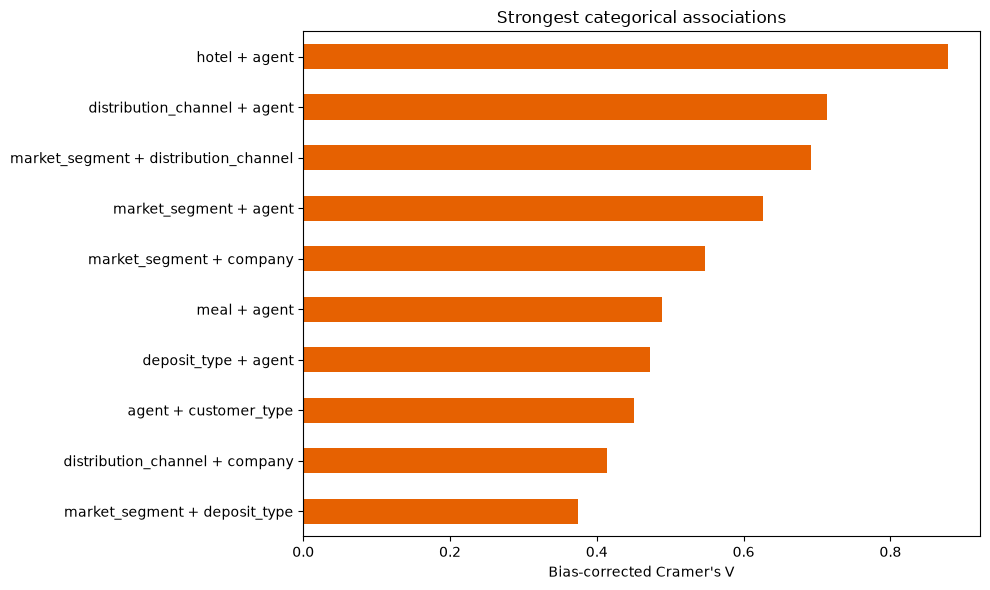

In [15]:
top_categorical = categorical_pairs.head(10).copy()
top_categorical["pair"] = top_categorical["feature_1"] + " + " + top_categorical["feature_2"]
fig, ax = plt.subplots(figsize=(10, 6))
top_categorical.sort_values("cramers_v").plot.barh(x="pair", y="cramers_v", ax=ax, legend=False, color="#e66101")
ax.set_title("Strongest categorical associations")
ax.set_xlabel("Bias-corrected Cramer's V")
ax.set_ylabel("")
fig.tight_layout()
plt.show()

add_chart_legend(ax)


## Conclusion

No numeric pair exceeded absolute Spearman correlation 0.80, and all numeric VIF values were below 1.4. Categorical associations were stronger, especially hotel-agent, distribution-channel-agent, and market-segment-distribution-channel. These results do not justify removing approved features or changing the selected 22-feature Random Forest interface. The Model Lead should perform a Choose-period sensitivity check and make any change using business cost and the walk-rate ceiling, not correlation alone.
